This project classifies breast masses as melignant or benign and uses data from https://www.kaggle.com/datasets/imtkaggleteam/breast-cancer/data. 

It is not synthetic data.

In [ ]:
#Import libraries
import pandas as pd
import numpy as np
from plotnine import *
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
# %pip install xgboost
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

In [81]:
df = pd.read_csv("breast-cancer.csv")
df

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [82]:
#Let us see how many benign and malignant cases we have in the dataset, as counts and percentages
df['diagnosis'].value_counts() , df['diagnosis'].value_counts(normalize=True)

(diagnosis
 B    357
 M    212
 Name: count, dtype: int64,
 diagnosis
 B    0.627417
 M    0.372583
 Name: proportion, dtype: float64)

In [83]:
#Let's change the diagnosis to a binary variable, where 1 is malignant and 0 is benign.
df['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})

In [84]:
train, test_temp = train_test_split(df, test_size=0.3, random_state=42)
test, val =  train_test_split(test_temp, test_size=0.5, random_state=42)


In [ ]:
y_train = train["diagnosis"]
X_train = train.drop(columns = ["id", "diagnosis"])
y_val = val["diagnosis"]
X_val = val.drop(columns = ["id", "diagnosis"])
y_test = test["diagnosis"]
X_test = test.drop(columns = ["id", "diagnosis"])

#scale the values by using StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)


In [86]:
#PCA on train
pca = PCA (n_components = 6)
X_train_PCA = pca.fit_transform(X_train)
print(f"Original data shape: {X_train.shape}")
print(f"Transformed data shape: {X_train_PCA.shape}")
print(f"Explained variance ratio: {pca.explained_variance_ratio_}")
print(f"Total variance explained: {sum(pca.explained_variance_ratio_):.2%}")


Original data shape: (398, 30)
Transformed data shape: (398, 6)
Explained variance ratio: [0.4316748  0.19845652 0.09733159 0.06531574 0.05212151 0.0419896 ]
Total variance explained: 88.69%


In [87]:
#With PCA we can reduce the dimensionality from 30 columns to 6 while still retaining 89% of the variance.
#Now we have done this, we can fit a random forest model to the transformed data and see how it performs, then test on the validation set.
#Now we should transform the validation and test sets using the same PCA transformation we fitted on the training set. This ensures that the model sees the same feature space during training and evaluation.
X_val_PCA = pca.transform(X_val)
X_test_PCA = pca.transform(X_test)


In [88]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Train the model on PCA-transformed training data
rf_model = RandomForestClassifier(
    n_estimators=500,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_model.fit(X_train_PCA, y_train);


In [89]:
def evaluate_model(model, X_val, y_val, model_name, positive_class=None):
    y_pred = model.predict(X_val)
    y_prob = model.predict_proba(X_val)

    # Determine the positive class for ROC-AUC
    classes = model.classes_

    if positive_class is None:
        positive_class = classes[1]

    positive_index = list(classes).index(positive_class)

    # Convert labels to binary for ROC-AUC
    y_val_binary = (y_val == positive_class).astype(int)
    y_prob_positive = y_prob[:, positive_index]

    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(
            y_val, y_pred,
            pos_label=positive_class,
            zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_pred,
            pos_label=positive_class,
            zero_division=0
        ),
        "F1 score": f1_score(
            y_val, y_pred,
            pos_label=positive_class,
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_val_binary, y_prob_positive)
    }

    print(f"\n{'=' * 60}")
    print(model_name)
    print(f"{'=' * 60}")

    print("\nMetrics:")
    display(
        pd.DataFrame([results]).set_index("Model").style.format("{:.4f}")
    )

    print("\nClassification report:")
    display(
        pd.DataFrame(
            classification_report(
                y_val,
                y_pred,
                output_dict=True,
                zero_division=0
            )
        ).T.round(4)
    )

    cm = confusion_matrix(y_val, y_pred, labels=classes)

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=classes,
        yticklabels=classes
    )
    plt.title(f"{model_name} - Validation Confusion Matrix")
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.tight_layout()
    plt.show()

    return results


Random Forest

Metrics:


,Accuracy,Precision,Recall,F1 score,ROC-AUC
Model,,,,,
Random Forest,0.9884,1.0000,0.9615,0.9804,1.0000



Classification report:


,precision,recall,f1-score,support
0,0.9836,1.0000,0.9917,60.0000
1,1.0000,0.9615,0.9804,26.0000
accuracy,0.9884,0.9884,0.9884,0.9884
macro avg,0.9918,0.9808,0.9861,86.0000
weighted avg,0.9886,0.9884,0.9883,86.0000


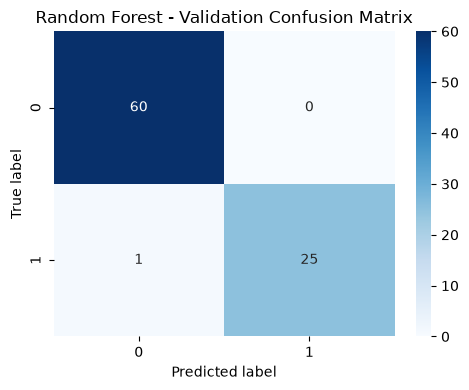

In [90]:
rf_results = evaluate_model(
    rf_model,
    X_val_PCA,
    y_val,
    "Random Forest",
    positive_class=1
)


XGBoost

Metrics:


,Accuracy,Precision,Recall,F1 score,ROC-AUC
Model,,,,,
XGBoost,0.9884,1.0000,0.9615,0.9804,1.0000



Classification report:


,precision,recall,f1-score,support
0,0.9836,1.0000,0.9917,60.0000
1,1.0000,0.9615,0.9804,26.0000
accuracy,0.9884,0.9884,0.9884,0.9884
macro avg,0.9918,0.9808,0.9861,86.0000
weighted avg,0.9886,0.9884,0.9883,86.0000


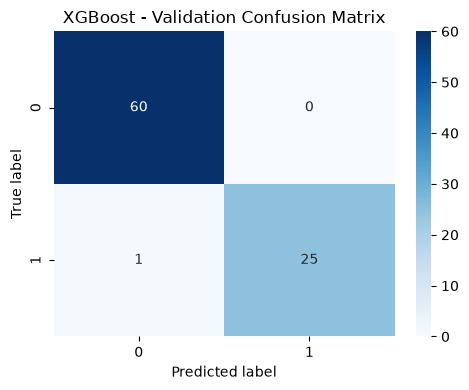

In [91]:
# Train an XGBoost model on the PCA-transformed data
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_PCA, y_train)

xgb_results = evaluate_model(
    xgb_model,
    X_val_PCA,
    y_val,
    "XGBoost",
    positive_class=1
)

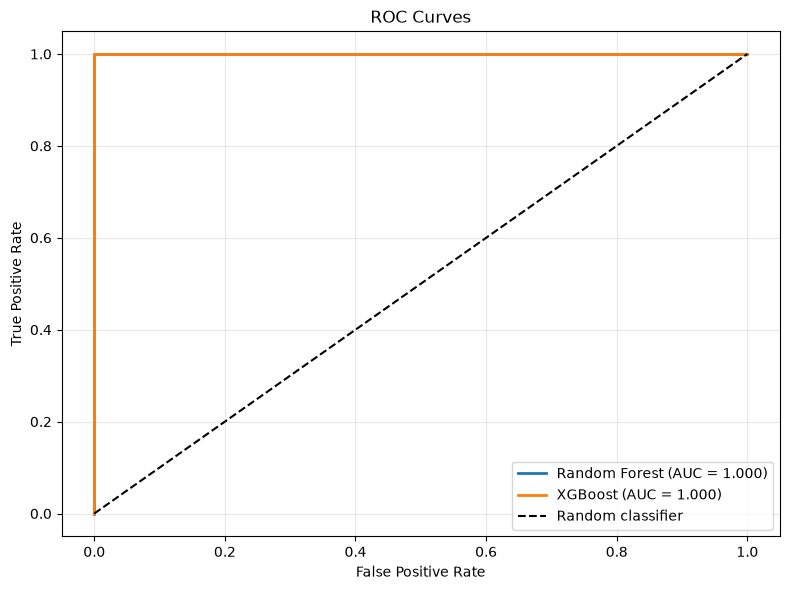

In [92]:
from sklearn.metrics import roc_curve

models = {
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

plt.figure(figsize=(8, 6))

for name, model in models.items():
    y_prob = model.predict_proba(X_val_PCA)[:, 1]
    fpr, tpr, _ = roc_curve(y_val, y_prob)
    auc_score = roc_auc_score(y_val, y_prob)

    plt.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {auc_score:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Both of the models do really well, as there is a class imbalance, xgboost should be useful, so I will use it as the final model and evaluate it on the test set.


XGBoost - Test Set

Metrics:


,Accuracy,Precision,Recall,F1 score,ROC-AUC
Model,,,,,
XGBoost - Test Set,0.9529,0.9459,0.9459,0.9459,0.9921



Classification report:


,precision,recall,f1-score,support
0,0.9583,0.9583,0.9583,48.0000
1,0.9459,0.9459,0.9459,37.0000
accuracy,0.9529,0.9529,0.9529,0.9529
macro avg,0.9521,0.9521,0.9521,85.0000
weighted avg,0.9529,0.9529,0.9529,85.0000


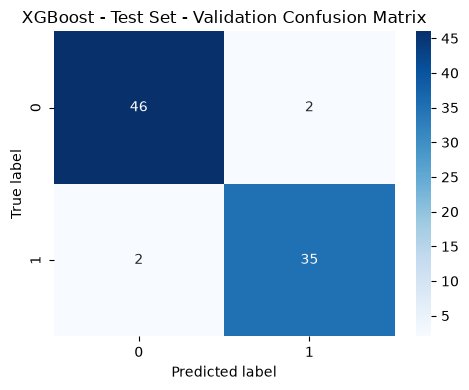

In [94]:
rf_test_results = evaluate_model(
    xgb_model,
    X_test_PCA,
    y_test,
    "XGBoost - Test Set",
    positive_class=1
)

,Feature,Importance
27,concave points_worst,0.133355
7,concave points_mean,0.123704
22,perimeter_worst,0.116436
23,area_worst,0.105708
20,radius_worst,0.075841
6,concavity_mean,0.069856
26,concavity_worst,0.053488
2,perimeter_mean,0.044483
0,radius_mean,0.037338
13,area_se,0.035560


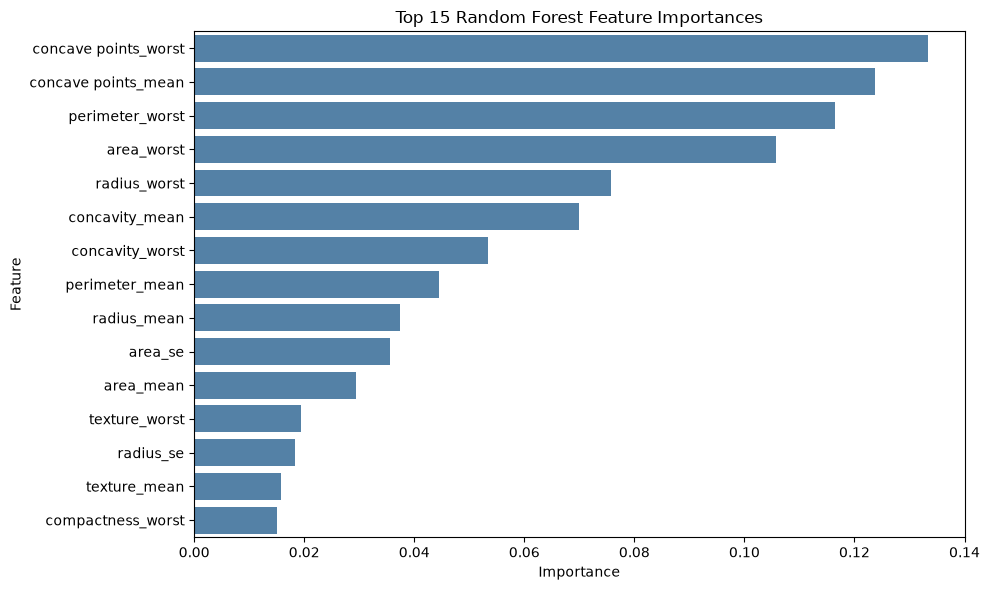

In [95]:
# Train a Random Forest using the original, non-PCA features
rf_non_pca = RandomForestClassifier(
    n_estimators=500,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_non_pca.fit(X_train, y_train)

# Rank features by importance
feature_importance = (
    pd.DataFrame({
        "Feature": x_train.columns,
        "Importance": rf_non_pca.feature_importances_
    })
    .sort_values("Importance", ascending=False)
)

display(feature_importance.head(15))

# Plot the 15 most important features
plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature",
    color="steelblue"
)
plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

Out of curiosity I am interested in if PCA and non PCA change the results


Random Forest - Non-PCA Test Set

Metrics:


,Accuracy,Precision,Recall,F1 score,ROC-AUC
Model,,,,,
Random Forest - Non-PCA Test Set,0.9765,0.9730,0.9730,0.9730,0.9983



Classification report:


,precision,recall,f1-score,support
0,0.9792,0.9792,0.9792,48.0000
1,0.9730,0.9730,0.9730,37.0000
accuracy,0.9765,0.9765,0.9765,0.9765
macro avg,0.9761,0.9761,0.9761,85.0000
weighted avg,0.9765,0.9765,0.9765,85.0000


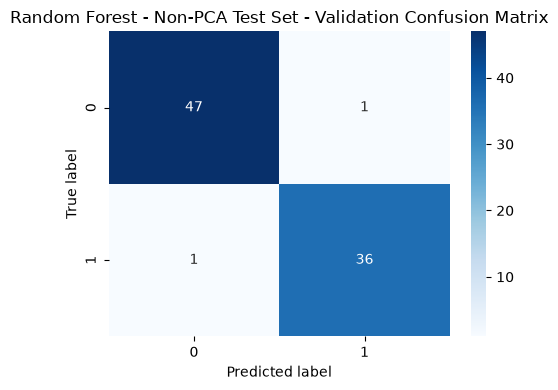

In [96]:
rf_non_pca_test_results = evaluate_model(
    rf_non_pca,
    X_test,
    y_test,
    "Random Forest - Non-PCA Test Set",
    positive_class=1
)

# Conclusion

We can see which features are important from this experiment (concave points are important).

If we compare this result to my skin cancer diagnosis workbook, we can see that this task was easier. Perhaps it is the tabular data instead of images, perhaps it is because breast cancer is just easier to detect than skin cancer.

(For the best results in the world, after selecting the best model, one could then train with both the training and validation before evaluating it on the test data)